In [5]:
import numpy as np
import random as random
import matplotlib.pyplot as plt

##### Código de ejercicios anteriores

In [2]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

x_fantoma = X_fantoma.reshape(-1)

def mascara_rayo(n, direccion, s):

    matriz = np.array([[0] * n for _ in range(n)])      # creamos una matriz de n x n de ceros

    for i in range(0, n):      
        for j in range(0, n):
            if direccion[0] * i + direccion[1] * j == s:        # comprobamos si el píxel (i, j) pertenece al rayo
                matriz[i, j] = 1        # si pertenece al rayo, marcamos esa posición con un 1

    return matriz       # devolvemos la máscara del rayo


def matriz_proyeccion(n, direcciones):

    matriz = []     # acá vamos a guardar los vectores de todas las máscaras
    rayo = []       # acá vamos a guardar los pares de s y (alfa, beta) de cada rayo

    for direccion in direcciones:

        valores_s = []      # acá guardamos todos los valores posibles de s para la dirección actual

        # recorremos todos los píxeles
        for i in range(n):
            for j in range(n):
                valores_s.append(direccion[0] * i + direccion[1] * j)       # calculamos el valor de s que le corresponde al píxel (i, j) para esta dirección

        valores_s = sorted(set(valores_s))      # eliminamos los valores repetidos de s y los ordenamos de menor a mayor

        for s in valores_s:

            rayo.append((tuple(direccion), s))

            mascara = mascara_rayo(n, direccion, s)     # generamos la máscara de este rayo particular
            matriz.append(mascara.reshape(-1))      # convertimos la máscara de n x n en un vector y lo agregamos como una nueva fila

    return np.array(matriz) , rayo

# D2
D2 = [(1, 0), (0, 1)]
A2, rayos_A2 = matriz_proyeccion(8, D2)
rango_A2 = np.linalg.matrix_rank(A2)
nul_A2 = 64 - rango_A2


# D4
D4 = D2 + [(1, 1), (1, -1)]
A4, rayos_A4 = matriz_proyeccion(8, D4)
rango_A4 = np.linalg.matrix_rank(A4)
nul_A4 = 64 - rango_A4

# D7
D7 = D4 + [(2, 1), (1, 2), (3, 1)]
A7, rayos_A7 = matriz_proyeccion(8, D7)
rango_A7 = np.linalg.matrix_rank(A7)
nul_A7 = 64 - rango_A7


### a)

In [35]:
#mediciones ideales
b7 = A7@x_fantoma

#seteo la semilla
np.random.seed(18)

#z del mismo tam que b7 con componentes gaussianas estandar
z = np.random.normal(0,1, len(b7))

# tam tipico de las mediciones
escala = np.sqrt(np.mean(b7**2))

#sigmas
sigma = [0, 0.01, 0.03, 0.06, 0.10]
b_sigmas = {}


for s in sigma:
    # "calibramos" el ruido
    n_sigma = s*escala*z
    
    # mediciones perturbadas (limpias + ruido)
    b_sigma = b7 + n_sigma
    
    #guardamos la tupla
    b_sigmas[s] = (n_sigma, b_sigma)
    print(f"Para sigma = {s:4.2f}: norma del ruido ||n_sigma|| = {np.linalg.norm(n_sigma):.4f}")

Para sigma = 0.00: norma del ruido ||n_sigma|| = 0.0000
Para sigma = 0.01: norma del ruido ||n_sigma|| = 0.1294
Para sigma = 0.03: norma del ruido ||n_sigma|| = 0.3881
Para sigma = 0.06: norma del ruido ||n_sigma|| = 0.7762
Para sigma = 0.10: norma del ruido ||n_sigma|| = 1.2937


### b)

sigma    ||n_sigma||    ||residuo||    Error Rel    Mín        Máx       
------------------------------------------------------------------
0.00     0.0000         0.0000         0.0000       -0.0000    0.8000    
0.01     0.1294         0.0907         0.0245       -0.0133    0.8077    
0.03     0.3881         0.2721         0.0736       -0.0398    0.8230    
0.06     0.7762         0.5442         0.1472       -0.0795    0.8459    
0.10     1.2937         0.9070         0.2453       -0.1326    0.8765    


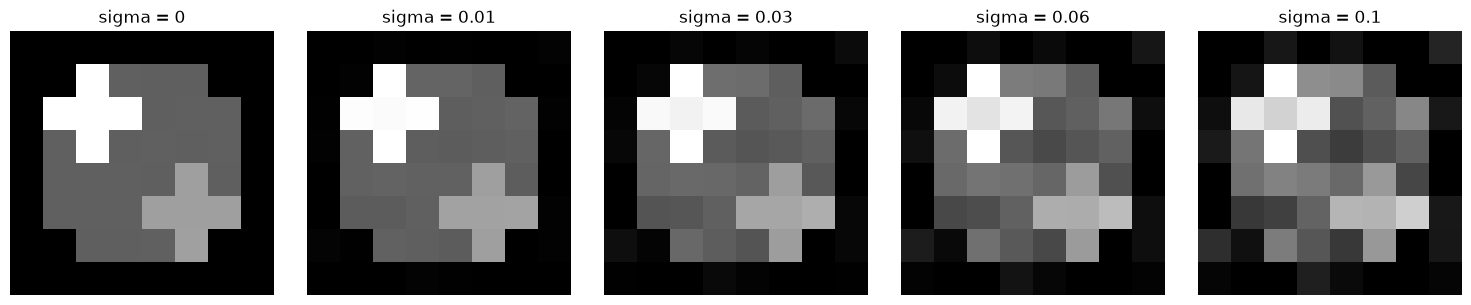

In [ ]:
resultados = []
imagenes = []

for s in sigma:
    #traigo los datos del for de arriba
    n_sigma, b_sigma = b_sigmas[s]
    
    #obtengo la reconstruccion x_raya_sigma
    x_raya_sigma = np.linalg.lstsq(A7, b_sigma, rcond=None)[0]
    imagenes.append(x_raya_sigma)
    
    # datos para la tabla
    norma_ruido = np.linalg.norm(n_sigma)
    residuo = b_sigma - A7 @ x_raya_sigma
    norma_residuo = np.linalg.norm(residuo)
    error_relativo = np.linalg.norm(x_raya_sigma - x_fantoma) / np.linalg.norm(x_fantoma)
    valor_min = x_raya_sigma.min()
    valor_max = x_raya_sigma.max()
    
    resultados.append((s, norma_ruido, norma_residuo, error_relativo, valor_min, valor_max))

# tabla
print(f"{'sigma':<8} {'||n_sigma||':<14} {'||residuo||':<14} {'Error Rel':<12} {'Mín':<10} {'Máx':<10}")
print("-" * 66)
for s, n_eta, n_res, err, v_min, v_max in resultados:
    print(f"{s:<8.2f} {n_eta:<14.4f} {n_res:<14.4f} {err:<12.4f} {v_min:<10.4f} {v_max:<10.4f}")

#imagenes
fix, axes = plt.subplots(1,5,figsize=(15,3))
for i, s in enumerate(sigma):
    im = axes[i].imshow(imagenes[i].reshape(8,8), cmap="gray", vmin=0, vmax=0.8)
    axes[i].set_title(f"sigma = {s}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

### c) Análisis de los resultados con ruido

1. **¿Cómo cambia el error de reconstrucción al aumentar $\sigma$?**
   A medida que el nivel de ruido $\sigma$ aumenta, el error relativo crece de forma prácticamente proporcional. Con $\sigma = 0$ el error es 0, pero al llegar a $\sigma = 0.10$ el error relativo sube a casi un 25%. Visualmente se puede ver cómo la imagen va perdiendo nitidez a causa del ruido

2. **¿Por qué el residuo deja de ser nulo cuando se agrega ruido?**
   Si no hay ruido, las mediciones $b_7$ vienen de una imagen real, por lo que existe una solución exacta que cumple las 119 ecuaciones a la vez ($A_7 x = b_7$) y el residuo es cero. 
   Al agregarle ruido aleatorio a cada sensor, las mediciones se vuelven inconsistentes entre sí. Como tenemos más ecuaciones que incógnitas ($119 > 64$), ya no hay ninguna imagen de 64 píxeles capaz de satisfacer todas las mediciones ruidosas a la vez. El método de mínimos cuadrados busca la mejor aproximación posible, pero la distancia entre lo que predice el modelo ($A_7 \hat{x}_\sigma$) y las mediciones ($b_\sigma$) ya no puede ser cero.

3. **¿Por qué pueden aparecer valores negativos?**
   La atenuación no puede ser negativa porque en el fantoma original los valores van de 0 a 0.8. Sin embargo, el método de mínimos cuadrados (`lstsq`) es un método matemático que permite que los píxeles tomen cualquier número real. Al intentar compensar las fluctuaciones aleatorias del ruido para que las sumas de los rayos den lo más cerca posible de $b_\sigma$, el algoritmo ajusta algunos píxeles hacia abajo, haciendo que en las zonas oscuras o de fondo aparezcan valores negativos (llegando a $-0.1326$ para $\sigma = 0.10$).